### 1.Website Selection

### Flipkart Mobile Products Web Scraping & Data Analysis

Website Selected: Flipkart

Website URL: https://www.flipkart.com/

Category Selected: Mobile Phones

Reason for Selection: Flipkart contains a large number of mobile phone products with useful information such as product name, rating, reviews, RAM, storage, price and discount.

This data can be used for data cleaning, exploratory data analysis, visualization and generating business insights.

### 2.Project Objective

The main objective of this project is to collect mobile phone product data from Flipkart using web scraping and perform data analysis on the collected data.

Objectives:

Collect mobile phone product information from Flipkart.
Understand the structure and characteristics of the scraped data.
Clean and preprocess the collected data.
Perform Exploratory Data Analysis (EDA).
Create meaningful visualizations.
Identify useful business insights.
Provide recommendations based on the analysis.

### 3.Data Collection
### 3.1. Import Libraries

In [9]:
import requests
from bs4 import BeautifulSoup
import pandas as pd
import re
import json

### 3.2.URL & Headers

In [10]:
url = "https://www.flipkart.com/search?q=mobile+phones"

headers = {
    "User-Agent": "Mozilla/5.0"
}

response = requests.get(url, headers=headers)

print(response.status_code)

200


### 3.3. Create BeautifulSoup Object

In [11]:
soup = BeautifulSoup(response.text, "html.parser")

print(soup.title.text)

Mobile Phones- Buy Products Online at Best Price in India - All Categories | Flipkart.com


### 3.4.Find ProductCard

In [12]:
product_cards = soup.find_all("div", class_="ZFwe0M")

print("Total product cards:", len(product_cards))

Total product cards: 24


### 3.5.Create DataFrame

In [13]:
data = []

for card in product_cards:
    text = card.get_text(" | ", strip=True)

    product_name = card.find("div", class_="RG5Slk")
    product_name = product_name.get_text(strip=True) if product_name else None

    rating = card.find("div", class_="MKiFS6")
    rating = rating.get_text(strip=True) if rating else None

    rating_count = re.search(r'([\d,]+)\s+Ratings', text)
    rating_count = rating_count.group(1) if rating_count else None

    review_count = re.search(r'([\d,]+)\s+Reviews', text)
    review_count = review_count.group(1) if review_count else None

    ram = re.search(r'(\d+\s*GB)\s+RAM', text)
    ram = ram.group(1) if ram else None

    storage = re.search(r'(\d+\s*GB)\s+ROM', text)
    storage = storage.group(1) if storage else None

    prices = re.findall(r'₹[\d,]+', text)

    price = prices[0] if len(prices) > 0 else None
    original_price = prices[1] if len(prices) > 1 else None

    discount = re.search(r'(\d+%)\s+off', text)
    discount = discount.group(1) if discount else None

    data.append({
        "Product_Name": product_name,
        "Rating": rating,
        "Rating_Count": rating_count,
        "Review_Count": review_count,
        "RAM": ram,
        "Storage": storage,
        "Price": price,
        "Original_Price": original_price,
        "Discount": discount
    })

df = pd.DataFrame(data)

### 3.6.Add Product URL

In [14]:
jsonld = soup.find("script", id="jsonLD")
data_json = json.loads(jsonld.string)

url_list = []

for item in data_json[0]["itemListElement"]:
    url_list.append(item["url"])

df["Product_URL"] = url_list

### 3.7.Check Dataset

In [15]:
print("Rows:", len(df))
print("Columns:", len(df.columns))

display(df.head())

Rows: 24
Columns: 10


,Product_Name,Rating,Rating_Count,Review_Count,RAM,Storage,Price,Original_Price,Discount,Product_URL
0,"BOLTT ACE 5G (Midnight Black, 64 GB)",4.1,878,314,4 GB,64 GB,"₹11,749","₹8,650",53%,https://www.flipkart.com/vivo-t5-lite-44w-5g-t...
1,"BOLTT EVO (Midnight Black, 64 GB)",4.2,"3,006","1,188",4 GB,64 GB,"₹9,749","₹7,250",45%,https://www.flipkart.com/ai-nova-2-neo-5g-oran...
2,"vivo T5x 5G (Cosmic Green, 128 GB)",4.4,"22,608","1,540",6 GB,128 GB,"₹27,499","₹22,425",40%,https://www.flipkart.com/samsung-galaxy-a36-5g...
3,"Apple iPhone 17 (Black, 256 GB)",4.6,"37,201","2,527",None,256 GB,"₹86,999","₹59,050",12%,https://www.flipkart.com/samsung-galaxy-f07-gr...
4,Samsung Galaxy S25 5G Snapdragon (Silver Shado...,4.6,"11,458","1,375",12 GB,128 GB,"₹56,999","₹43,400",45%,https://www.flipkart.com/vivo-t5x-5g-flame-red...


### 3.8. Save Raw Dataset

In [16]:
df.to_csv("flipkart_mobile_raw_data.csv", index=False)

print("CSV file saved successfully!")

CSV file saved successfully!


### 4.Data Understanding

### 4.1 Dataset Overview

In [17]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nFirst 5 Rows:")
display(df.head())

Dataset Shape: (24, 10)

Column Names:
['Product_Name', 'Rating', 'Rating_Count', 'Review_Count', 'RAM', 'Storage', 'Price', 'Original_Price', 'Discount', 'Product_URL']

Data Types:
Product_Name      object
Rating            object
Rating_Count      object
Review_Count      object
RAM               object
Storage           object
Price             object
Original_Price    object
Discount          object
Product_URL       object
dtype: object

First 5 Rows:


,Product_Name,Rating,Rating_Count,Review_Count,RAM,Storage,Price,Original_Price,Discount,Product_URL
0,"BOLTT ACE 5G (Midnight Black, 64 GB)",4.1,878,314,4 GB,64 GB,"₹11,749","₹8,650",53%,https://www.flipkart.com/vivo-t5-lite-44w-5g-t...
1,"BOLTT EVO (Midnight Black, 64 GB)",4.2,"3,006","1,188",4 GB,64 GB,"₹9,749","₹7,250",45%,https://www.flipkart.com/ai-nova-2-neo-5g-oran...
2,"vivo T5x 5G (Cosmic Green, 128 GB)",4.4,"22,608","1,540",6 GB,128 GB,"₹27,499","₹22,425",40%,https://www.flipkart.com/samsung-galaxy-a36-5g...
3,"Apple iPhone 17 (Black, 256 GB)",4.6,"37,201","2,527",None,256 GB,"₹86,999","₹59,050",12%,https://www.flipkart.com/samsung-galaxy-f07-gr...
4,Samsung Galaxy S25 5G Snapdragon (Silver Shado...,4.6,"11,458","1,375",12 GB,128 GB,"₹56,999","₹43,400",45%,https://www.flipkart.com/vivo-t5x-5g-flame-red...


### 4.2 Misiing Values

In [18]:
print("Missing Values")
print(df.isnull().sum())

Missing Values
Product_Name      0
Rating            0
Rating_Count      0
Review_Count      0
RAM               2
Storage           1
Price             0
Original_Price    1
Discount          1
Product_URL       0
dtype: int64


### 4.3 Duplicate VAlues Analysis

In [21]:
print("Total Duplicate Rows:",df.duplicated().sum())

Total Duplicate Rows: 0


### 4.4 Basic Statistics Summary

In [22]:
df.describe()

,Product_Name,Rating,Rating_Count,Review_Count,RAM,Storage,Price,Original_Price,Discount,Product_URL
count,24,24,24,24,22,23,24,23,23,24
unique,23,8,16,16,4,3,17,15,13,24
top,"vivo T5 Lite 44W 5G (Wave Blue, 128 GB)",4.4,"22,608","1,540",4 GB,128 GB,"₹27,499","₹22,425",45%,https://www.flipkart.com/vivo-t5-lite-44w-5g-t...
freq,2,5,3,3,8,15,3,3,4,1


### 4.5 Data Types & Column information

In [23]:
print(df.dtypes)

Product_Name      object
Rating            object
Rating_Count      object
Review_Count      object
RAM               object
Storage           object
Price             object
Original_Price    object
Discount          object
Product_URL       object
dtype: object


### 5.Data Cleaning
### 5.1 Remove Unnecessary Spaces

In [24]:
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].str.strip()

print("Unnecessary spaces removed.")

Unnecessary spaces removed.


## 5.2 Clean Price Columns
#### Convert Price columns to numeric

In [25]:
df["Price"] = (
    df["Price"]
    .str.replace("₹", "", regex=False)
    .str.replace(",", "", regex=False)
)

df["Original_Price"] = (
    df["Original_Price"]
    .str.replace("₹", "", regex=False)
    .str.replace(",", "", regex=False)
)

df["Price"] = pd.to_numeric(df["Price"], errors="coerce")
df["Original_Price"] = pd.to_numeric(df["Original_Price"], errors="coerce")

print(df[["Price", "Original_Price"]].head())
print(df[["Price", "Original_Price"]].dtypes)

   Price  Original_Price
0  11749          8650.0
1   9749          7250.0
2  27499         22425.0
3  86999         59050.0
4  56999         43400.0
Price               int64
Original_Price    float64
dtype: object


### 5.3 Convert Discount to Numeric

In [26]:
df["Discount"] = (
    df["Discount"]
    .str.replace("%", "", regex=False)
)

df["Discount"] = pd.to_numeric(df["Discount"], errors="coerce")

print(df["Discount"].head())
print("\nData Type:", df["Discount"].dtype)

0    53.0
1    45.0
2    40.0
3    12.0
4    45.0
Name: Discount, dtype: float64

Data Type: float64


### 5.4 Convert Rating to Numeric 

In [27]:
df["Rating"] = pd.to_numeric(df["Rating"], errors="coerce")

print(df["Rating"].head())
print("\nData Type:", df["Rating"].dtype)

0    4.1
1    4.2
2    4.4
3    4.6
4    4.6
Name: Rating, dtype: float64

Data Type: float64


### 5.5 Convert Rating Count and Review Count to Numeric

In [28]:
df["Rating_Count"] = (
    df["Rating_Count"]
    .str.replace(",", "", regex=False)
)

df["Review_Count"] = (
    df["Review_Count"]
    .str.replace(",", "", regex=False)
)

df["Rating_Count"] = pd.to_numeric(df["Rating_Count"], errors="coerce")
df["Review_Count"] = pd.to_numeric(df["Review_Count"], errors="coerce")

print(df[["Rating_Count", "Review_Count"]].head())
print("\nData Types:")
print(df[["Rating_Count", "Review_Count"]].dtypes)

   Rating_Count  Review_Count
0           878           314
1          3006          1188
2         22608          1540
3         37201          2527
4         11458          1375

Data Types:
Rating_Count    int64
Review_Count    int64
dtype: object


### 5.6 Convert RAM and Storage to Numeric

In [29]:
df["RAM"] = (
    df["RAM"]
    .str.replace("GB", "", regex=False)
    .str.strip()
)

df["Storage"] = (
    df["Storage"]
    .str.replace("GB", "", regex=False)
    .str.strip()
)

df["RAM"] = pd.to_numeric(df["RAM"], errors="coerce")
df["Storage"] = pd.to_numeric(df["Storage"], errors="coerce")

print(df[["RAM", "Storage"]].head())
print("\nData Types:")
print(df[["RAM", "Storage"]].dtypes)

    RAM  Storage
0   4.0     64.0
1   4.0     64.0
2   6.0    128.0
3   NaN    256.0
4  12.0    128.0

Data Types:
RAM        float64
Storage    float64
dtype: object


### 5.7 Missing Values After Cleaning

In [30]:
print("Missing Values After Cleaning:")
print(df.isnull().sum())

Missing Values After Cleaning:
Product_Name      0
Rating            0
Rating_Count      0
Review_Count      0
RAM               2
Storage           1
Price             0
Original_Price    1
Discount          1
Product_URL       0
dtype: int64


### 5.8. Handling Missing Values 

In [31]:
df["RAM"] = df["RAM"].fillna(df["RAM"].median())
df["Storage"] = df["Storage"].fillna(df["Storage"].median())
df["Original_Price"] = df["Original_Price"].fillna(df["Original_Price"].median())
df["Discount"] = df["Discount"].fillna(df["Discount"].median())

print("Missing values handled successfully.")

print("\nMissing Values After Handling:")
print(df.isnull().sum())

Missing values handled successfully.

Missing Values After Handling:
Product_Name      0
Rating            0
Rating_Count      0
Review_Count      0
RAM               0
Storage           0
Price             0
Original_Price    0
Discount          0
Product_URL       0
dtype: int64


### 5.9 Check Data Types After Cleaning

In [32]:
print("Data Types After Cleaning:")
print(df.dtypes)

Data Types After Cleaning:
Product_Name       object
Rating            float64
Rating_Count        int64
Review_Count        int64
RAM               float64
Storage           float64
Price               int64
Original_Price    float64
Discount          float64
Product_URL        object
dtype: object


### 5.10 Final Duplicate Check 

In [33]:
print("Total Duplicate Rows:",df.duplicated().sum())

Total Duplicate Rows: 0


### 5.11 Final Cleaned Dataset Check

In [34]:
print("Final Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nFirst 5 Rows:")
display(df.head())

Final Dataset Shape: (24, 10)

Column Names:
['Product_Name', 'Rating', 'Rating_Count', 'Review_Count', 'RAM', 'Storage', 'Price', 'Original_Price', 'Discount', 'Product_URL']

Data Types:
Product_Name       object
Rating            float64
Rating_Count        int64
Review_Count        int64
RAM               float64
Storage           float64
Price               int64
Original_Price    float64
Discount          float64
Product_URL        object
dtype: object

First 5 Rows:


,Product_Name,Rating,Rating_Count,Review_Count,RAM,Storage,Price,Original_Price,Discount,Product_URL
0,"BOLTT ACE 5G (Midnight Black, 64 GB)",4.1,878,314,4.0,64.0,11749,8650.0,53.0,https://www.flipkart.com/vivo-t5-lite-44w-5g-t...
1,"BOLTT EVO (Midnight Black, 64 GB)",4.2,3006,1188,4.0,64.0,9749,7250.0,45.0,https://www.flipkart.com/ai-nova-2-neo-5g-oran...
2,"vivo T5x 5G (Cosmic Green, 128 GB)",4.4,22608,1540,6.0,128.0,27499,22425.0,40.0,https://www.flipkart.com/samsung-galaxy-a36-5g...
3,"Apple iPhone 17 (Black, 256 GB)",4.6,37201,2527,6.0,256.0,86999,59050.0,12.0,https://www.flipkart.com/samsung-galaxy-f07-gr...
4,Samsung Galaxy S25 5G Snapdragon (Silver Shado...,4.6,11458,1375,12.0,128.0,56999,43400.0,45.0,https://www.flipkart.com/vivo-t5x-5g-flame-red...


### 5.12 Verify Product URLs

In [35]:
for card in product_cards[:5]:
    link = card.find("a", href=True)
    print(link.get("href") if link else None)

None
None
None
None
None


 ### Temporarily Remove Incorrect URLs

In [36]:
df["Product_URL"] = None
print(df["Product_URL"].head())

0    None
1    None
2    None
3    None
4    None
Name: Product_URL, dtype: object


### 5.13 Final Missing Value Check

In [37]:
print("Final Missing Values:")
print(df.isnull().sum())

Final Missing Values:
Product_Name       0
Rating             0
Rating_Count       0
Review_Count       0
RAM                0
Storage            0
Price              0
Original_Price     0
Discount           0
Product_URL       24
dtype: int64


### Remove Unusable Product URL Column

In [38]:
df = df.drop(columns=["Product_URL"])

print("Product_URL column removed.")
print("\nFinal Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

Product_URL column removed.

Final Shape: (24, 9)

Columns:
['Product_Name', 'Rating', 'Rating_Count', 'Review_Count', 'RAM', 'Storage', 'Price', 'Original_Price', 'Discount']


### 6.Exploratory Data Analysis(EDA)
#### 6.1. Descriptive Statistics

In [39]:
df.describe()

,Rating,Rating_Count,Review_Count,RAM,Storage,Price,Original_Price,Discount
count,24.000000,24.000000,24.000000,24.000000,24.000000,24.000000,24.000000,24.000000
mean,4.316667,9579.416667,904.250000,6.416667,130.666667,28473.166667,22610.416667,36.208333
std,0.225864,8809.789786,619.444369,2.569329,54.955054,20415.632739,14019.568848,10.150944
min,3.700000,878.000000,122.000000,4.000000,64.000000,1079.000000,7250.000000,12.000000
25%,4.200000,3167.000000,301.500000,4.000000,128.000000,12749.000000,9800.000000,31.000000
50%,4.300000,6993.000000,853.500000,6.000000,128.000000,24249.000000,20400.000000,40.000000
75%,4.425000,11458.000000,1375.250000,8.000000,128.000000,34249.000000,27200.000000,43.500000
max,4.600000,37201.000000,2527.000000,12.000000,256.000000,86999.000000,59050.000000,53.000000


### 6.2 price Distribution

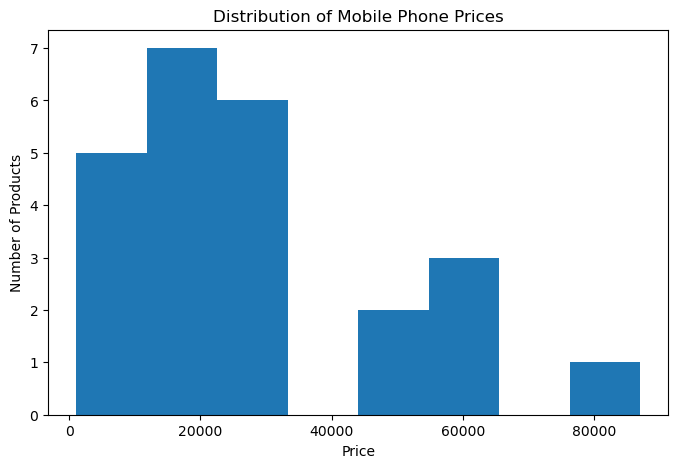

In [40]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.hist(df["Price"], bins=8)
plt.xlabel("Price")
plt.ylabel("Number of Products")
plt.title("Distribution of Mobile Phone Prices")
plt.show()

### 6.3 Rating Distribution

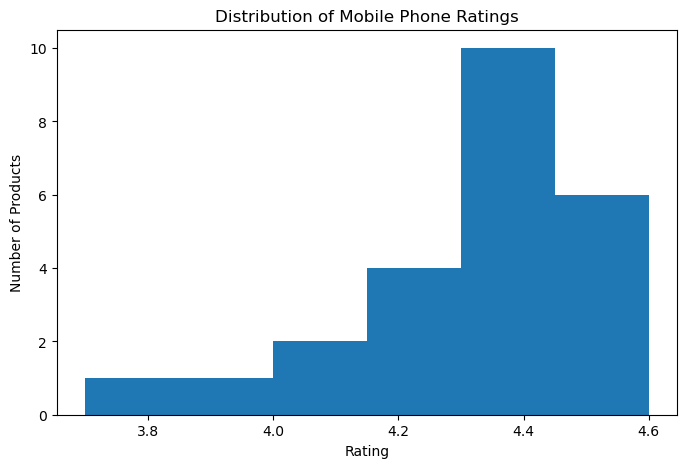

In [41]:
plt.figure(figsize=(8, 5))

plt.hist(df["Rating"], bins=6)

plt.xlabel("Rating")
plt.ylabel("Number of Products")
plt.title("Distribution of Mobile Phone Ratings")

plt.show()

### 6.4 RAM Distribution 

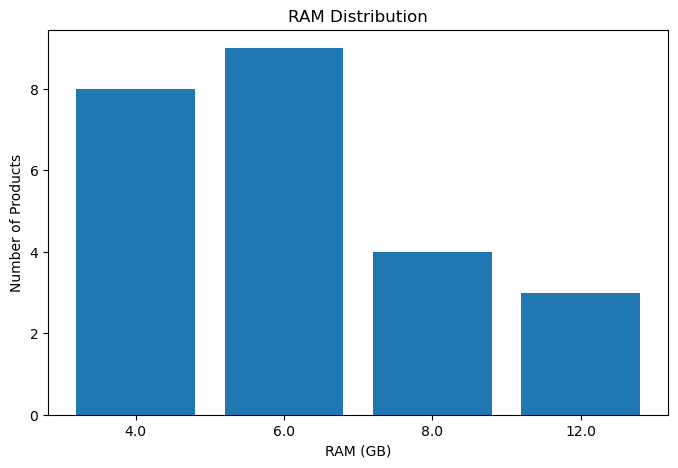

In [42]:
ram_counts = df["RAM"].value_counts().sort_index()

plt.figure(figsize=(8, 5))

plt.bar(ram_counts.index.astype(str), ram_counts.values)

plt.xlabel("RAM (GB)")
plt.ylabel("Number of Products")
plt.title("RAM Distribution")

plt.show()

### 6.5 Storage Distribution 

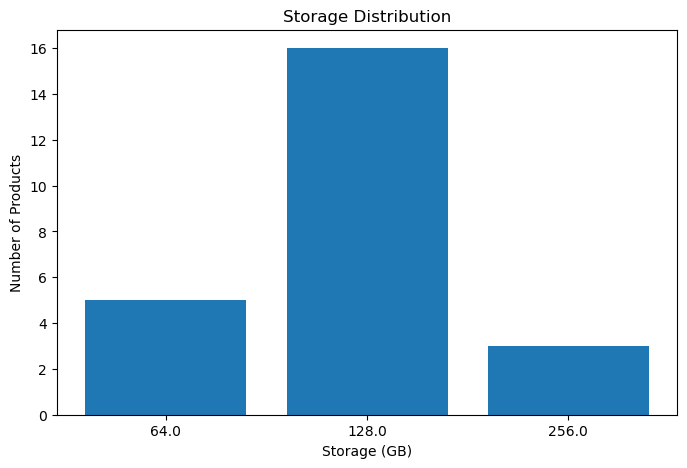

In [43]:
storage_counts = df["Storage"].value_counts().sort_index()

plt.figure(figsize=(8, 5))

plt.bar(storage_counts.index.astype(str), storage_counts.values)

plt.xlabel("Storage (GB)")
plt.ylabel("Number of Products")
plt.title("Storage Distribution")

plt.show()

### 6.6 Discount Analysis

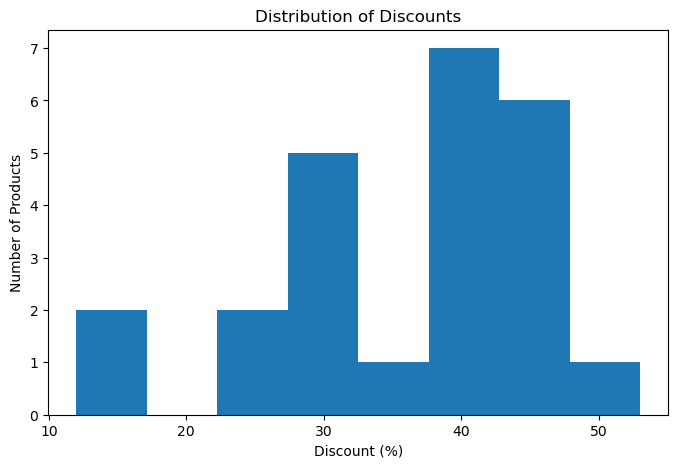

In [44]:
plt.figure(figsize=(8, 5))

plt.hist(df["Discount"], bins=8)

plt.xlabel("Discount (%)")
plt.ylabel("Number of Products")
plt.title("Distribution of Discounts")

plt.show()

### 6.7 Price VS Rating

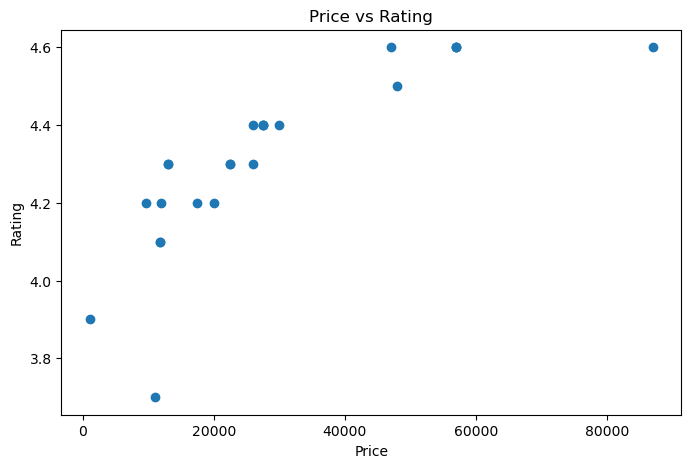

In [45]:
plt.figure(figsize=(8, 5))

plt.scatter(df["Price"], df["Rating"])

plt.xlabel("Price")
plt.ylabel("Rating")
plt.title("Price vs Rating")

plt.show()

### 6.8 Price VS Discount

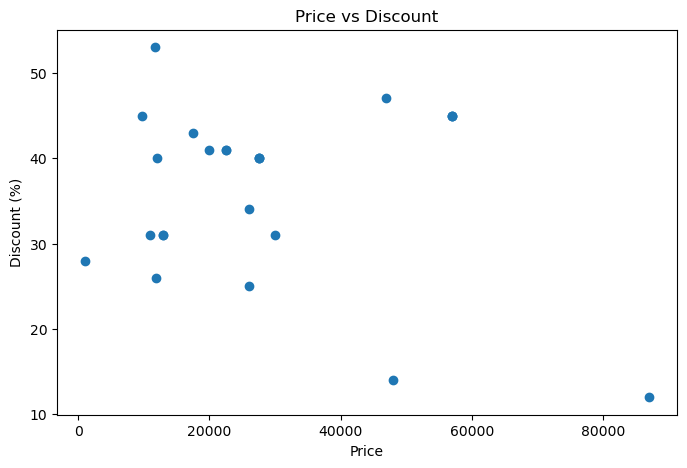

In [46]:
plt.figure(figsize=(8, 5))

plt.scatter(df["Price"], df["Discount"])

plt.xlabel("Price")
plt.ylabel("Discount (%)")
plt.title("Price vs Discount")

plt.show()

### 6.9 Price VS Rating Count

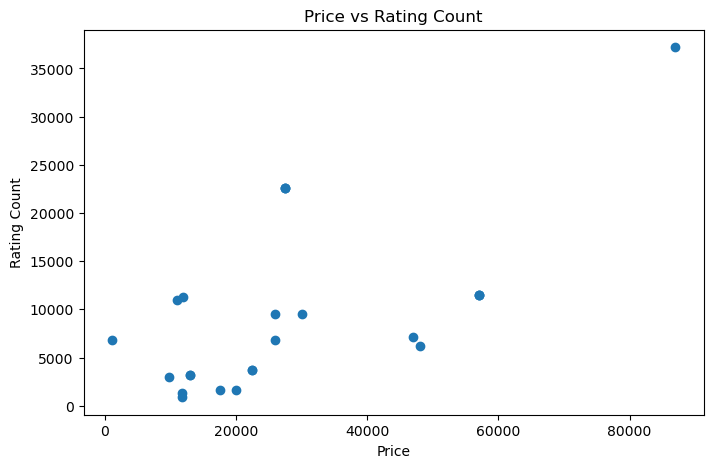

In [47]:
plt.figure(figsize=(8, 5))

plt.scatter(df["Price"], df["Rating_Count"])

plt.xlabel("Price")
plt.ylabel("Rating Count")
plt.title("Price vs Rating Count")

plt.show()

### 6.10 Avg price by RAM

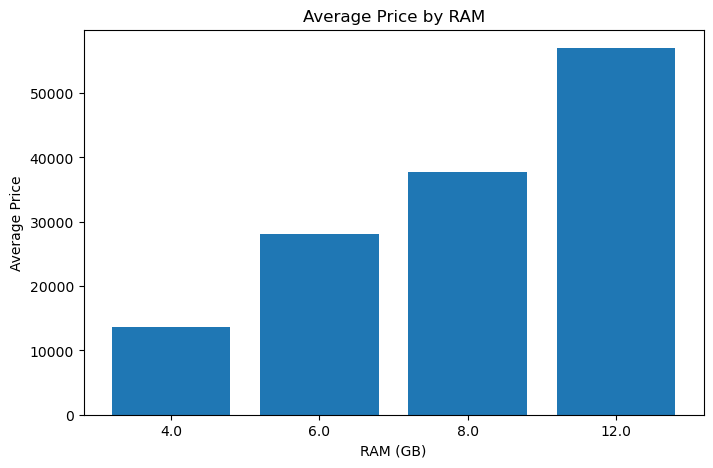

In [48]:
avg_price_ram = df.groupby("RAM")["Price"].mean()

plt.figure(figsize=(8, 5))

plt.bar(avg_price_ram.index.astype(str), avg_price_ram.values)

plt.xlabel("RAM (GB)")
plt.ylabel("Average Price")
plt.title("Average Price by RAM")

plt.show()

### 6.11 AVG Price by Storage

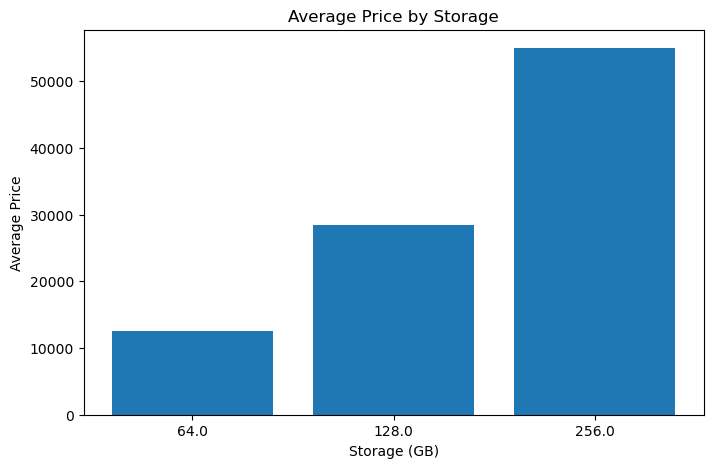

In [49]:
avg_price_storage = df.groupby("Storage")["Price"].mean()

plt.figure(figsize=(8, 5))

plt.bar(avg_price_storage.index.astype(str), avg_price_storage.values)

plt.xlabel("Storage (GB)")
plt.ylabel("Average Price")
plt.title("Average Price by Storage")

plt.show()

### 6.12 Correlation Analysis

In [50]:
correlation = df.select_dtypes(include="number").corr()

display(correlation)

,Rating,Rating_Count,Review_Count,RAM,Storage,Price,Original_Price,Discount
Rating,1.000000,0.398378,0.490501,0.616853,0.422206,0.809882,0.765632,0.047725
Rating_Count,0.398378,1.000000,0.884185,0.236526,0.449055,0.601578,0.593479,-0.277164
Review_Count,0.490501,0.884185,1.000000,0.476141,0.439748,0.664027,0.656384,-0.145829
RAM,0.616853,0.236526,0.476141,1.000000,0.346518,0.684369,0.753845,0.133224
Storage,0.422206,0.449055,0.439748,0.346518,1.000000,0.592081,0.620901,-0.644508
Price,0.809882,0.601578,0.664027,0.684369,0.592081,1.000000,0.962591,-0.192388
Original_Price,0.765632,0.593479,0.656384,0.753845,0.620901,0.962591,1.000000,-0.212547
Discount,0.047725,-0.277164,-0.145829,0.133224,-0.644508,-0.192388,-0.212547,1.000000


### 6.13 Correlation Heatmap

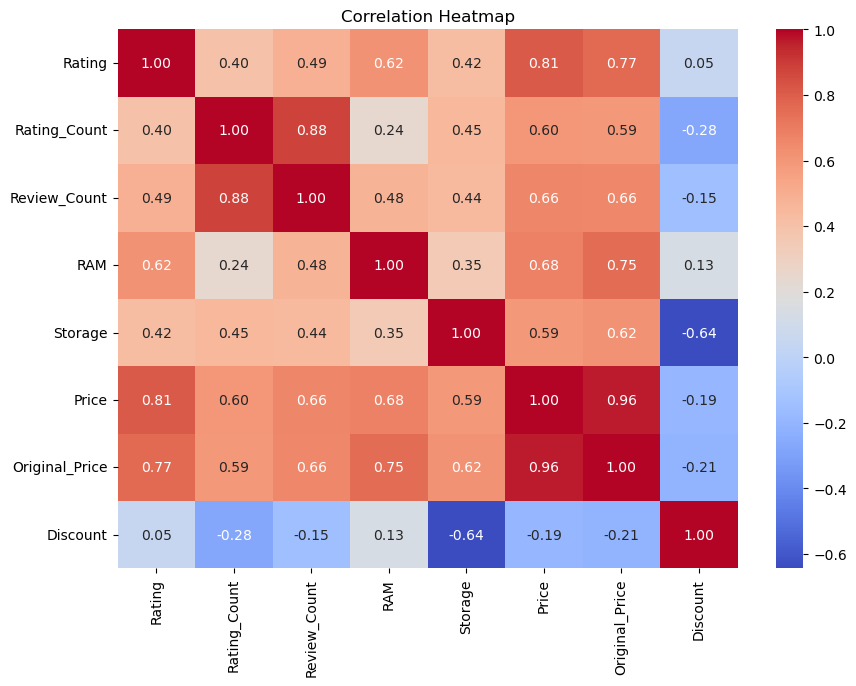

In [51]:
import seaborn as sns

plt.figure(figsize=(10, 7))

sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f")

plt.title("Correlation Heatmap")

plt.show()

### 6.14 Top Rated Products

In [52]:
top_rated = df.sort_values("Rating", ascending=False)[
    ["Product_Name", "Rating", "Rating_Count", "Price"]
].head(10)

display(top_rated)

,Product_Name,Rating,Rating_Count,Price
10,"Samsung Galaxy S25 5G Snapdragon (Mint, 128 GB)",4.6,11458,56999
3,"Apple iPhone 17 (Black, 256 GB)",4.6,37201,86999
4,Samsung Galaxy S25 5G Snapdragon (Silver Shado...,4.6,11458,56999
5,"Samsung Galaxy S25 5G Snapdragon (Icyblue, 128...",4.6,11458,56999
20,"Samsung Galaxy S25 FE 5G (Navy, 128 GB)",4.6,7165,46999
11,"Google Pixel 10a (Fog, 256 GB)",4.5,6202,47999
2,"vivo T5x 5G (Cosmic Green, 128 GB)",4.4,22608,27499
6,"Samsung Galaxy A36 5G (Dark Blue, 128 GB)",4.4,9522,25999
22,"vivo T5x 5G (Flame Red, 128 GB)",4.4,22608,27499
16,"Samsung Galaxy A36 5G (Dark Blue, 256 GB)",4.4,9522,29999


### 6.15 Most Reviewed Products

In [53]:
most_reviewed = df.sort_values("Review_Count", ascending=False)[
    ["Product_Name", "Review_Count", "Rating", "Price"]
].head(10)

display(most_reviewed)

,Product_Name,Review_Count,Rating,Price
3,"Apple iPhone 17 (Black, 256 GB)",2527,4.6,86999
2,"vivo T5x 5G (Cosmic Green, 128 GB)",1540,4.4,27499
22,"vivo T5x 5G (Flame Red, 128 GB)",1540,4.4,27499
15,"vivo T5x 5G (Satin Silver, 128 GB)",1540,4.4,27499
16,"Samsung Galaxy A36 5G (Dark Blue, 256 GB)",1376,4.4,29999
6,"Samsung Galaxy A36 5G (Dark Blue, 128 GB)",1376,4.4,25999
4,Samsung Galaxy S25 5G Snapdragon (Silver Shado...,1375,4.6,56999
5,"Samsung Galaxy S25 5G Snapdragon (Icyblue, 128...",1375,4.6,56999
10,"Samsung Galaxy S25 5G Snapdragon (Mint, 128 GB)",1375,4.6,56999
1,"BOLTT EVO (Midnight Black, 64 GB)",1188,4.2,9749


### 6.16 Highest Discount Products

In [54]:
highest_discount = df.sort_values("Discount", ascending=False)[
    ["Product_Name", "Price", "Original_Price", "Discount"]
].head(10)

display(highest_discount)

,Product_Name,Price,Original_Price,Discount
0,"BOLTT ACE 5G (Midnight Black, 64 GB)",11749,8650.0,53.0
20,"Samsung Galaxy S25 FE 5G (Navy, 128 GB)",46999,35300.0,47.0
10,"Samsung Galaxy S25 5G Snapdragon (Mint, 128 GB)",56999,43400.0,45.0
4,Samsung Galaxy S25 5G Snapdragon (Silver Shado...,56999,43400.0,45.0
5,"Samsung Galaxy S25 5G Snapdragon (Icyblue, 128...",56999,43400.0,45.0
1,"BOLTT EVO (Midnight Black, 64 GB)",9749,7250.0,45.0
18,"vivo T5 Lite 44W 5G (Twilight Shadow, 64 GB)",17499,13400.0,43.0
21,"vivo T5 Lite 44W 5G (Twilight Shadow, 128 GB)",22499,18225.0,41.0
14,"vivo T5 Lite 44W 5G (Wave Blue, 128 GB)",22499,18225.0,41.0
23,"vivo T5 Lite 44W 5G (Wave Blue, 128 GB)",19999,15900.0,41.0


### Step 6.17: EDA Summary

The Exploratory Data Analysis helped identify pricing patterns,
customer rating patterns, popular RAM and storage configurations,
discount patterns and relationships between numerical variables.

The analysis also identified highly rated products, most reviewed
products and products with the highest discounts.

These findings will be used to create visualizations and generate
business insights and recommendations.

### 7.Data Visualization

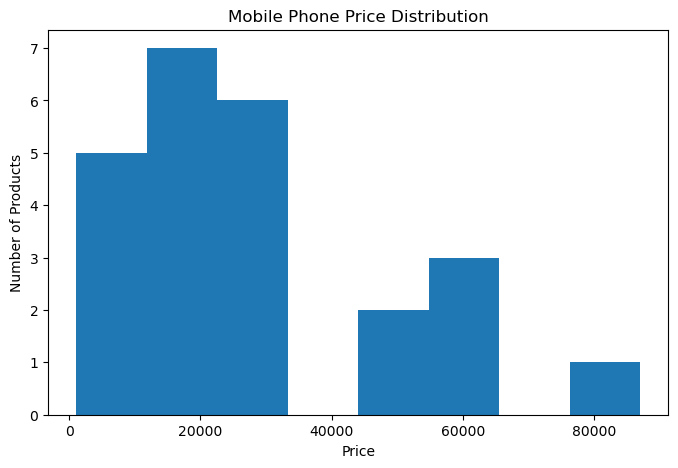

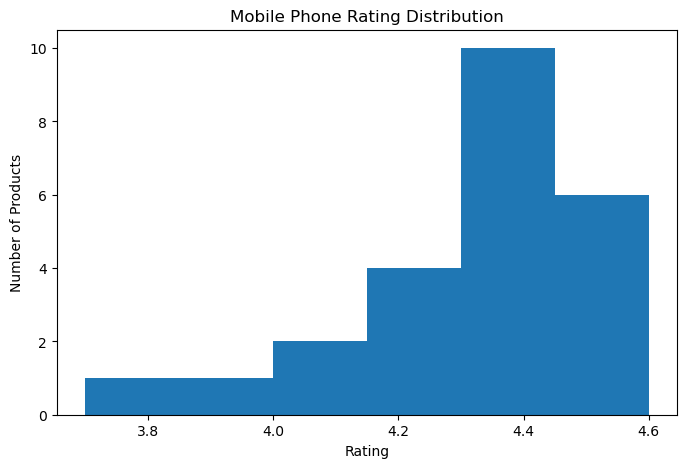

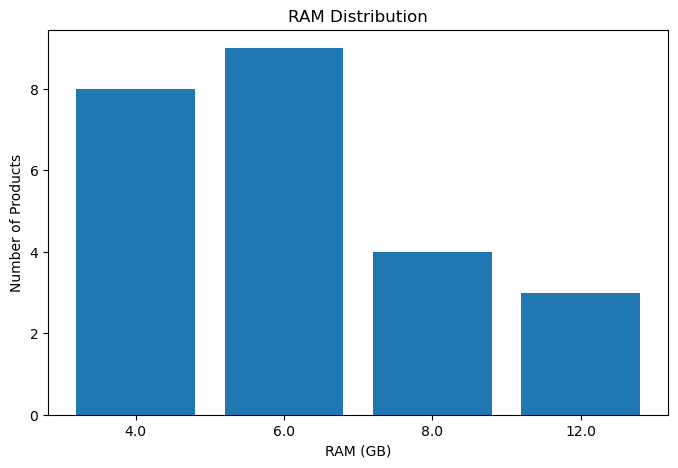

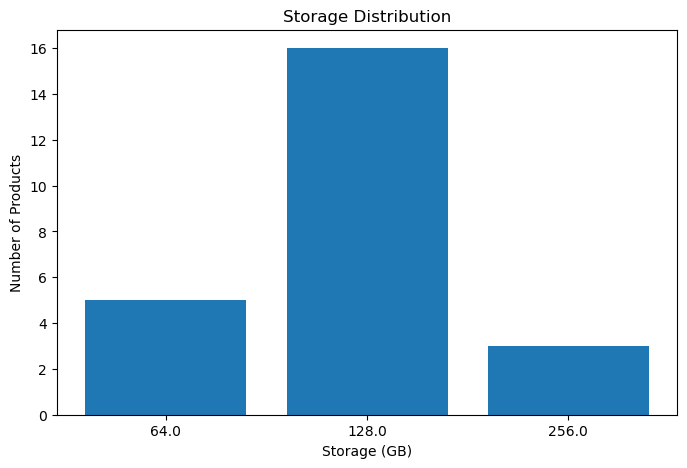

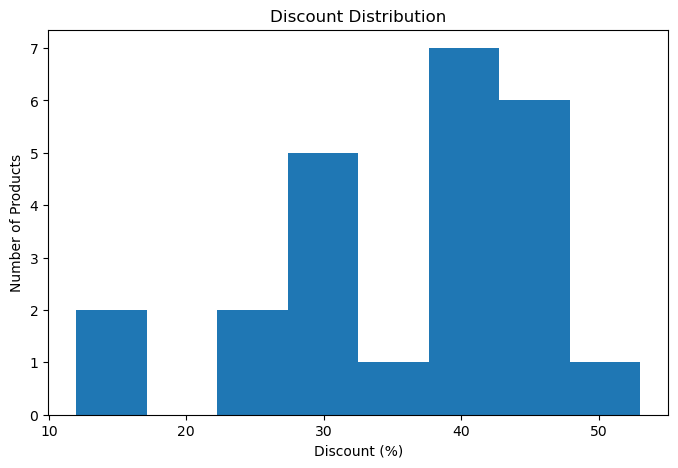

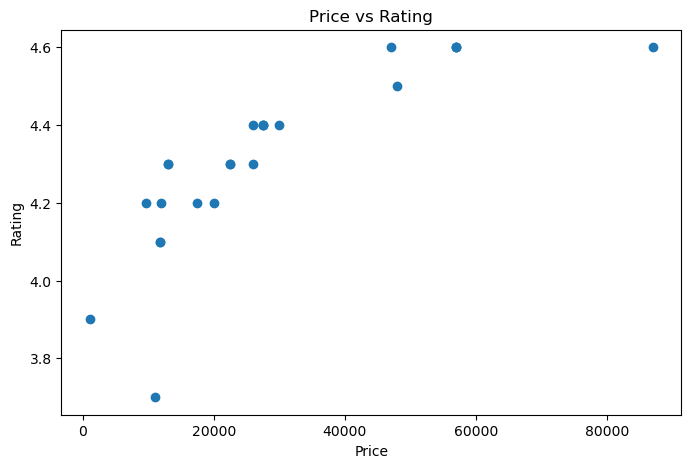

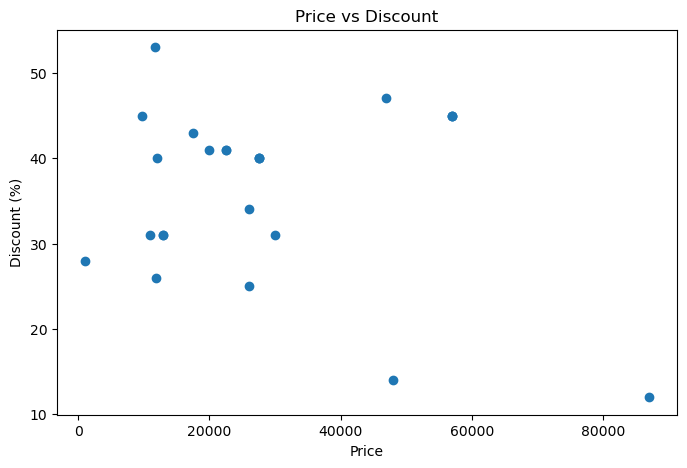

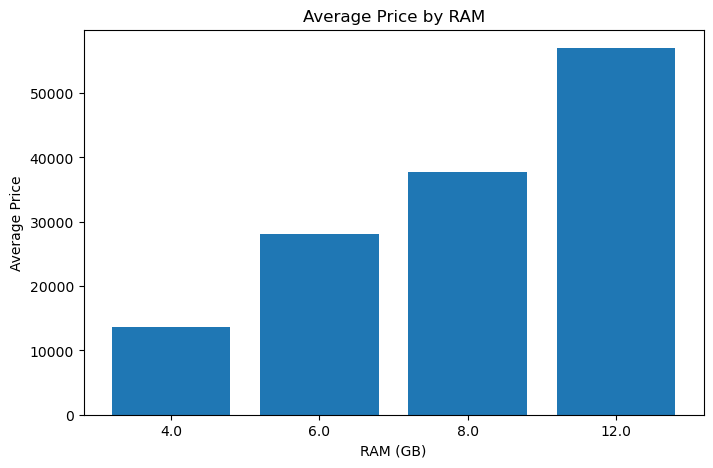

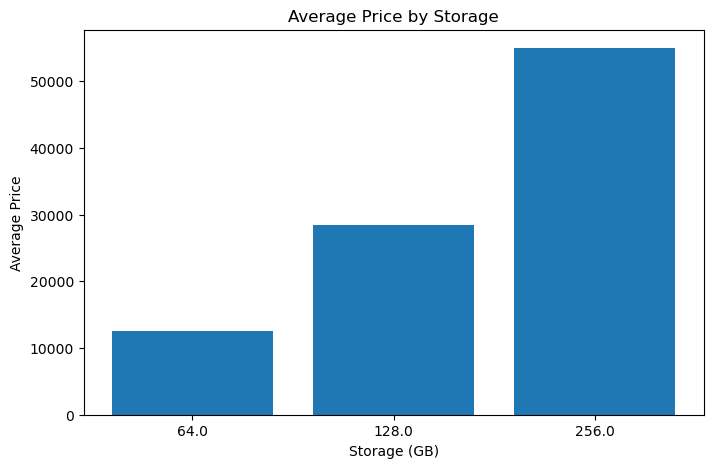

In [55]:
# 1. Price Distribution
plt.figure(figsize=(8, 5))
plt.hist(df["Price"], bins=8)
plt.xlabel("Price")
plt.ylabel("Number of Products")
plt.title("Mobile Phone Price Distribution")
plt.show()


# 2. Rating Distribution
plt.figure(figsize=(8, 5))
plt.hist(df["Rating"], bins=6)
plt.xlabel("Rating")
plt.ylabel("Number of Products")
plt.title("Mobile Phone Rating Distribution")
plt.show()


# 3. RAM Distribution
ram_counts = df["RAM"].value_counts().sort_index()

plt.figure(figsize=(8, 5))
plt.bar(ram_counts.index.astype(str), ram_counts.values)
plt.xlabel("RAM (GB)")
plt.ylabel("Number of Products")
plt.title("RAM Distribution")
plt.show()


# 4. Storage Distribution
storage_counts = df["Storage"].value_counts().sort_index()

plt.figure(figsize=(8, 5))
plt.bar(storage_counts.index.astype(str), storage_counts.values)
plt.xlabel("Storage (GB)")
plt.ylabel("Number of Products")
plt.title("Storage Distribution")
plt.show()


# 5. Discount Distribution
plt.figure(figsize=(8, 5))
plt.hist(df["Discount"], bins=8)
plt.xlabel("Discount (%)")
plt.ylabel("Number of Products")
plt.title("Discount Distribution")
plt.show()


# 6. Price vs Rating
plt.figure(figsize=(8, 5))
plt.scatter(df["Price"], df["Rating"])
plt.xlabel("Price")
plt.ylabel("Rating")
plt.title("Price vs Rating")
plt.show()


# 7. Price vs Discount
plt.figure(figsize=(8, 5))
plt.scatter(df["Price"], df["Discount"])
plt.xlabel("Price")
plt.ylabel("Discount (%)")
plt.title("Price vs Discount")
plt.show()


# 8. Average Price by RAM and Storage

avg_price_ram = df.groupby("RAM")["Price"].mean()

plt.figure(figsize=(8, 5))
plt.bar(avg_price_ram.index.astype(str), avg_price_ram.values)
plt.xlabel("RAM (GB)")
plt.ylabel("Average Price")
plt.title("Average Price by RAM")
plt.show()

avg_price_storage = df.groupby("Storage")["Price"].mean()

plt.figure(figsize=(8, 5))
plt.bar(avg_price_storage.index.astype(str), avg_price_storage.values)
plt.xlabel("Storage (GB)")
plt.ylabel("Average Price")
plt.title("Average Price by Storage")
plt.show()

# Step 8: Business Insights & Recommendations

### 8.1 Business Insights

Based on the EDA and visualizations, the following important
business insights were identified from the Flipkart mobile phone data.

1. Higher-priced mobile phones generally have higher customer ratings.
2. Products with higher rating counts also tend to have higher review counts.
3. Higher RAM and storage configurations are generally associated with higher prices.
4. Discounts vary across products, with some products offering significantly higher discounts.
5. Price and original price have a very strong positive relationship.
6. Discount percentage has a very weak relationship with customer ratings.


### 8.2 Key Findings

| Area | Key Finding |
|---|---|
| Price | Higher-priced phones generally receive higher ratings |
| Ratings | Ratings are generally in the higher range |
| Reviews | Products with more ratings tend to have more reviews |
| RAM | Higher RAM configurations generally have higher prices |
| Storage | Higher storage configurations generally have higher prices |
| Discount | Discount percentages vary across products |
| Price & Original Price | Very strong positive relationship |
| Discount & Rating | Very weak relationship |


### 8.3 Business Recommendations

1. Promote highly rated products to improve customer trust.
2. Highlight products with high ratings and a large number of reviews.
3. Offer competitive discounts on selected products to attract customers.
4. Maintain a strong product range across different RAM and storage configurations.
5. Use customer ratings and reviews to identify popular products.
6. Monitor pricing and discount strategies to improve sales performance.


### 8.4 Final Conclusion

The Flipkart mobile phone analysis provides useful insights into
product pricing, customer ratings, reviews, RAM, storage and discounts.

The analysis shows that product price is strongly related to customer
rating and product specifications. Products with higher ratings and
more customer reviews can be considered strong-performing products.

These insights can help businesses improve product promotion,
pricing strategies, discount planning and product selection.

# Step 9: Final Report / Presentation

### 9.1 Project Summary

This project focuses on scraping mobile phone product data from
Flipkart and analyzing the collected data using Python.

A dataset of 24 mobile phone products was collected and analyzed
based on product name, rating, rating count, review count, RAM,
storage, price, original price and discount.

The data was cleaned, analyzed using EDA techniques and presented
through meaningful visualizations.


### 9.2 Tools & Technologies Used

The following tools and technologies were used in this project:

- Python
- Jupyter Notebook
- Requests
- BeautifulSoup
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Flipkart website


### 9.3 Key Findings

The major findings from the analysis are:

- Higher-priced mobile phones generally have higher ratings.
- Rating Count and Review Count have a strong positive relationship.
- Higher RAM configurations generally have higher prices.
- Higher storage configurations generally have higher prices.
- Price and Original Price have a very strong positive relationship.
- Discount percentage varies across different products.
- Discount and Rating have a very weak relationship.
- The dataset contains 24 mobile phone products.


### 9.4 Conclusion

The Flipkart Mobile Products Web Scraping & Data Analysis project
successfully demonstrates the complete data analysis workflow.

The project includes website selection, web scraping, data
understanding, data cleaning, exploratory data analysis,
visualization and business insights.

The analysis provides useful information about mobile phone pricing,
customer ratings, reviews, RAM, storage and discounts.

These insights can help businesses understand product trends,
improve pricing strategies, plan discounts and identify
popular products.